# 11 线性回归分析

> **模块**：回归分析 ｜ **数据**：`fire.csv`、`pressure.csv` ｜ **依赖**：numpy、matplotlib、scipy、scikit-learn、statsmodels

## 1. 问题背景

回归分析是一种多元统计分析的方法，目的在于了解两个或多个变量间是否相关、相关方向与强度，并建立数学模型以便观察特定变量以预测研究者感兴趣的变量。在实际问题中，一个变量往往受到多个变量的影响，此时需要用两个或两个以上的影响因素作为自变量来解释因变量的变化。当多个变量与因变量之间是线性关系时，所进行的回归分析就是多元线性回归。


## 2. 学习目标

- 掌握一元线性回归的思路和基本方法
- 掌握多元线性回归的思路和基本方法


## 3. 环境与数据

- Jupyter 开发环境
- Python 3.10


## 4. 方法与实现

### 4.1 一元线性回归分析

一元线性回归也称为简单线性回归，是一种根据单一自变量 $x$ 预测因变量 $y$ 的方法。

在实际问题的研究中，经常需要研究某一现象与影响它的某一最主要因素的关系。比如，影响粮食产量的因素非常多，但在众多因素中，施肥量是最重要的因素之一，因此往往会研究施肥量这一因素与粮食产量之间的关系。

**例1**. 假设某一保险公司希望确定居民住宅区火灾造成的损失数额与该住户到最近消防站的距离之间的相关关系，以便确定出保险金额。下表列出了15起火灾事故的损失及火灾发生地与最近消防站的距离。将下表中数据（不算表头）保存到 `fire.csv` 文件中。试确定一个一元线性回归模型。假如一住户到最近消防站的距离为7km，那么试预测若发生火灾，火灾损失为多少千元？

| 距消防站的距离 $x$ (km) | 火灾损失 $y$ (千元) |
|-------------------------|---------------------|
| 3.4                     | 26.2                |
| 1.8                     | 17.8                |
| 4.6                     | 31.3                |
| 2.3                     | 23.1                |
| 3.1                     | 27.5                |
| 5.5                     | 36                  |
| 0.7                     | 14.1                |
| 3                       | 22.3                |
| 2.6                     | 19.6                |
| 4.3                     | 31.3                |
| 2.1                     | 24                  |
| 1.1                     | 17.3                |
| 6.1                     | 43.2                |
| 4.8                     | 36.4                |
| 3.8                     | 26.1                |

*表1: 火灾损失与距离消防站距离的数据表*


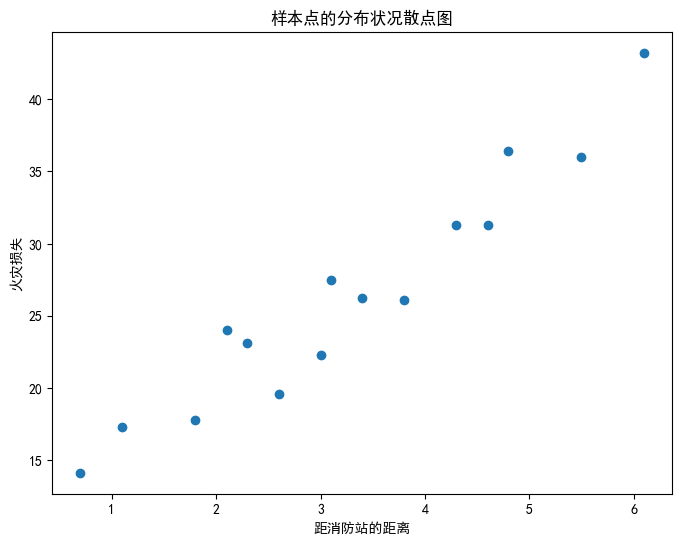

In [1]:
import numpy as np, matplotlib.pyplot as plt, pandas as pd
fire = np.loadtxt("../data/fire.csv",delimiter=',')
#fire = pd.read_csv("../data/fire.csv",delimiter=',')
plt.rcParams['font.sans-serif']=['SimHei'] 
plt.rc('axes',unicode_minus=False)
plt.figure(figsize=(8,6))
plt.title('样本点的分布状况散点图')
plt.xlabel('距消防站的距离')
plt.ylabel('火灾损失')
plt.scatter(fire[:,0], fire[:,1])
# plt.scatter(fire.iloc[:,0], fire.iloc[:,1])
plt.show()  

从上图可以看出，样本数据点大致分布在一条直线附近，这说明变量和变量之间具有明显的线性关系。

同时，这些样本点的分布并不完全在一条直线上，表明x与y的关系并没有确切到给定x就可以确定唯一y的程度。

每个样本点与直线的偏差可以看做其他随机因素的影响，因此可以做如下式的假定：

$$y = β_0+β_1x+ε$$
- $β_0+β_1x$表示y随x变化而线性变化的部分
- $ε$是随机误差，也称为残差，它是其他随机因素影响的总和，其值不可观测
- $β_0$和$β_1$统称为回归参数，其中$β_0$为回归常数，$β_1$为回归系数

回归分析的主要任务是通过n组样本观测值$(x_i,y_i)(i=1,2,...,n)$对$β_0$和$β_1$进行估计，使用$\hat{β}_0$和$\hat{β}_1$分别表示$β_0$和$β_1$的估计值，那么下式称为y关于x的一元线性回归方程：

$$\hat{y} = \hat{β}_0+\hat{β}_1x$$

为了得到回归参数的理想估计值$\hat{β}_0$和$\hat{β}_1x$，通常使用普通**最小二乘（OLS）法**进行估计。

对于每一个样本观测值$(x_i,y_i)$，使用最小二乘法进行估计的思路是观测值$y_i$与其回归值$\hat{y}_i = \hat{β}_0+\hat{β}_1x_i$的离差越小越好。

#### 4.1.1 最小二乘法估计回归参数

最后得到$β_0$和$β_1$的估计值化简式如下：

$$
\begin{cases}{\hat{β}_0 =  \overline{y}-\hat{β}_1\overline{x}}\\
{\hat{β}_1 = \frac{L_{xy}}{L_{xx}}}\\
\end{cases}

$$

- $\overline{x} = \frac{1}{n}\sum_{i=1}^{n}{x_i}$,$\overline{y} = \frac{1}{n}\sum_{i=1}^{n}{y_i}$
- $L_{xx} = \sum_{i=1}^{n}{{x_i}^2}-n{(\overline{x})}^2$,$L_{xy} = \sum_{i=1}^{n}{x_iy_i}-n\overline{x}\overline{y}$

In [2]:
# 先提取自变量x和因变量y
x = fire[:,0]
y = fire[:,1]
# 计算样本均值
x_mean = np.mean(x)
y_mean = np.mean(y)
# 计算Lxx和Lxy
Lxx = np.sum(x**2)-x.shape[0]*(x_mean)**2
Lxy = np.matmul(x, y)-x.shape[0]*x_mean*y_mean
# 计算回归系数β1和β0
β1 = Lxy/Lxx
β0 = y_mean-β1*x_mean
print('β1={},β0={}'.format(β1,β0))

β1=4.919330726770931,β0=10.277928549524685


在Python中，使用普通最小二乘法拟合直线通常有以下四种方法：

1. **scipy.optimize.least_squares**
   ```python
   scipy.optimize.least_squares(fun, x0, method='trf', loss='linear', ...)
   ```
- **fun(x, *args, **kwargs)**：残差计算函数。
- **x0**：估计参数的初始值。
- **loss**：损失函数，默认值为'linear'，表示线性损失。

2. **statsmodels.api.OLS**
   ```python
   statsmodels.api.OLS(endog, exog=None, missing='none', hasconst=None)
   ```
- **endog**：表示因变量 $y$ 的数据。
- **exog**：表示自变量的一个数组，可以选择性地包括截距项（使用 `statsmodels.api.add_constant` 函数添加）。

3. **statsmodels.api.formula.ols**
   ```python
   statsmodels.api.formula.ols(formula, data)
   ```
- **formula**：模型的公式，例如 `'y ~ x1 + x2'`。
- **data**：数据集。

4. **sklearn.linear_model.LinearRegression**
   ```python
   sklearn.linear_model.LinearRegression(fit_intercept=True, normalize=False, copy_X=True, n_jobs=1)
   ```
- **fit_intercept**：是否计算模型的截距。如果参数值为 `True`，则训练模型时需要加一个截距项；若参数值为 `False`，则模型无需加截距项。
- **normalize**：如果 `fit_intercept` 参数设置为 `False`，则 `normalize` 参数无需设置；如果 `normalize` 设置为 `True`，则输入的样本数据将使用标准化处理，即 $(X - X_{\text{均值}})/||X||$。

In [3]:
from scipy import optimize
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression


#方法一：可以用线性拟合的方法估计参数
# 定义残差函数=真实值-拟合值
def regula(p):
    a,b = p
    return y - a - b*x
# least_squares()放入残差函数，和拟合参数的初始值
result1 = optimize.least_squares(regula,[0,0])
print('回归参数的估计值为：',result1.x)

# 方法二：使用OLS()
# 使用 sm.add_constant() 加入一列截距列
X = sm.add_constant(fire[:,0])
# 拟合数据放入y和x（带截距）
model = sm.OLS(fire[:,1], X)
# 获取拟合结果
result2 = model.fit()
# 调取计算出的回归系数
print('回归参数的估计值为：',result2.params)

# 方法三：使用formula.ols()
# 定义字典，放入自变量，因变量的值
df = {'x':fire[:,0],'y':fire[:,1]}
# 放入模型公式字符和数据
result3 =sm.formula.ols('y~x',data=df).fit()
print('回归参数的估计值为：\n',result3.params)

# 方法四：使用LinearRegression()
md = LinearRegression()
md.fit(x.reshape(-1,1),y)
print('回归参数的估计值为：\n',md.intercept_,md.coef_[0])

回归参数的估计值为： [10.27792854  4.91933073]
回归参数的估计值为： [10.27792855  4.91933073]
回归参数的估计值为：
 Intercept    10.277929
x             4.919331
dtype: float64
回归参数的估计值为：
 10.277928549524692 4.919330726770929


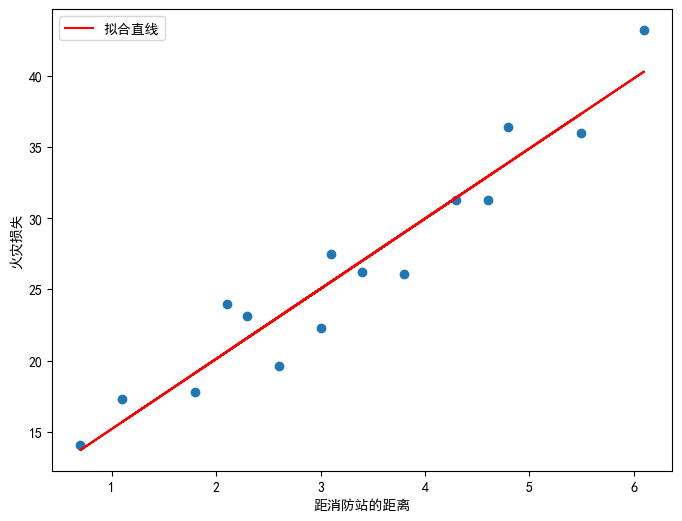

In [4]:
# 设置绘图画布大小
plt.figure(figsize=(8,6))
plt.xlabel('距消防站的距离')
plt.ylabel('火灾损失')
plt.scatter(x, y)
y_pre = md.predict(x.reshape(-1,1))
plt.plot(x, y_pre,'r-',label="拟合直线")
plt.legend()
plt.show()  

#### 4.1.2 显著性检验

得到一个实际问题的回归 $\hat{y} = \hat{β}_0 + \hat{β}_1 x$ 后，还不能马上用它去做分析和预测，因为 $\hat{y} = \hat{β}_0 + \hat{β}_1 x$ 是否真正可以描述变量 y 与 x 之间的统计规律，还需要对回归方程进行检验。

以下检验的前提是正态性假设 $ε_i \sim N(0, δ^2)$。

1. **t 检验：回归系数的显著性检验**

$$
H_0: β_1 = 0, \quad H_1: β_1 \neq 0

$$

回归系数的显著性检验就是要检验自变量 x 对因变量 y 的影响程度是否显著。如果原假设 $H_0$ 成立，则因变量 y 与自变量 x 之间没有真正的线性关系，即自变量 x 的变化对因变量 y 并没有影响。

2. **F 检验：回归方程的显著性检验**

$$
H_0: \text{回归方程系数全为零}, \quad H_1: \text{回归方程系数不全为零}

$$

F 检验统计量：

$$
F = \frac{SSR / 1}{SSE / (n - 2)}

$$
- $n$：样本数
- $SSR$：回归平方和
- $SSE$：残差平方和

当原假设 $H_0$ 成立时，$F$ 服从自由度为 $(1, n - 2)$ 的 $F$ 分布。给定显著性水平 $α$，可以得到 $F$ 检验的临界值 $F_α(1, n - 2)$。

当 $F > F_α(1, n - 2)$ 时，拒绝原假设 $H_0$，说明回归方程显著，x 与 y 有显著的线性关系。

另外也可以根据 P 值做检验，$P \text{值} = P(F > F \text{值})$，对比 P 值和 $1 - α$ 值判断是否拒绝原假设。

In [5]:
# 使用OLS类下fit函数的summary方法可查看t检验和F检验的结果
print('检验的结果为：\n',result2.summary())

检验的结果为：
                             OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.923
Model:                            OLS   Adj. R-squared:                  0.918
Method:                 Least Squares   F-statistic:                     156.9
Date:                Fri, 07 Aug 2026   Prob (F-statistic):           1.25e-08
Time:                        01:57:21   Log-Likelihood:                -32.811
No. Observations:                  15   AIC:                             69.62
Df Residuals:                      13   BIC:                             71.04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         10.2779      1.420      7.237

d:\CodingRation\10-Python数学建模\Python_mathematical_modeling\.venv\lib\site-packages\scipy\stats\_stats_py.py:1736: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=15
  warnings.warn("kurtosistest only valid for n>=20 ... continuing "


由以上看出：$\hat{β}_0$的标准误差为1.420，$\hat{β}_1$的标准误差为0.393；$t$统计量的值为12.525，对应p值为0；$F$统计量的值为156.9，对应p值为$1.25×10^{-8}$。因为$t$统计量和$F$统计量对应的p值均小于显著性水平0.05，所以应该拒绝原假设，认为火灾损失对距消防站距离的一元线性归回的效果显著。

#### 4.1.3 参数区间估计

求参数$\hat{β}_0,\hat{β}_1$在显著性水平为5%下的区间估计

$\hat{β}_i(i=0,1)$的区间估计为：

$$[\hat{β}_i-\sqrt{Var(\hat{β}_i)}t_{\frac{α}{2}}(n-2),\hat{β}_i+\sqrt{Var(\hat{β}_i)}t_{\frac{α}{2}}(n-2)]$$

In [6]:
from scipy.stats import t
# 设置显著性水平为0.05
alpha = 0.05
n = len(x)
# s = t.isf(1-alpha, n)返回值s就是alpha分位数,满足：t.cdf(s, n) = alpha(cdf：累计分布函数) 
sem = t.isf(alpha/2,n-2)
# 设置参数值和标准误差 result3.params获取参数值
b0 = result3.params[0]
b0_std = 1.420
b1 = result3.params[1]
b1_std = 0.393
print('参数β0的区间估计为：',[b0-b0_std*sem,b0+b0_std*sem])
print('参数β1的区间估计为：',[b1-b1_std*sem,b1+b1_std*sem])

参数β0的区间估计为： [7.21020505735005, 13.345652041699326]
参数β1的区间估计为： [4.070305844781751, 5.768355608760108]


C:\Users\yohoten\AppData\Local\Temp\ipykernel_37164\2132588634.py:8: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  b0 = result3.params[0]
C:\Users\yohoten\AppData\Local\Temp\ipykernel_37164\2132588634.py:10: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  b1 = result3.params[1]


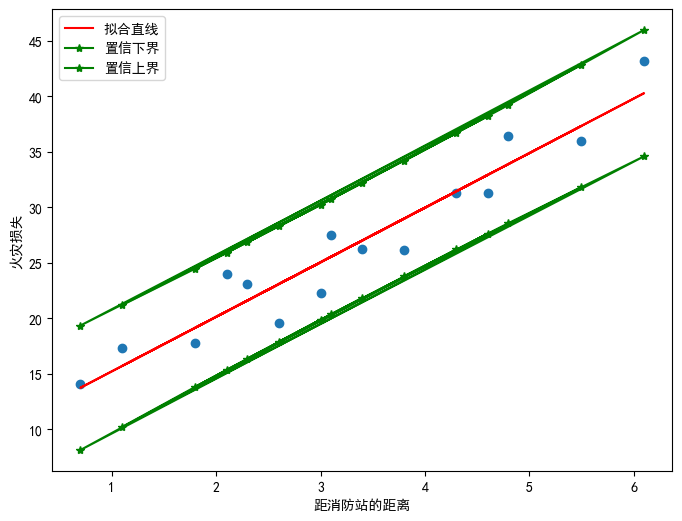

In [7]:
from statsmodels.sandbox.regression.predstd import wls_prediction_std
# wls_prediction_std(housing_model)返回三个值,标准差，置信区间下限，置信区间上限
_,ivLow, ivUp = wls_prediction_std(result2)
# 设置绘图画布大小
plt.figure(figsize=(8,6))
plt.xlabel('距消防站的距离')
plt.ylabel('火灾损失')
plt.scatter(x, y)
y_pre = md.predict(x.reshape(-1,1))
plt.plot(x, y_pre,'r-',label="拟合直线")
plt.plot(x, ivLow,'g-*',label="置信下界")
plt.plot(x, ivUp,'g-*',label="置信上界")
plt.legend()
plt.show()  

#### 4.1.4 预测

In [8]:
# 放入预测数据
x_test = np.array([[7]])
# 预测
pre = md.predict(x_test)
print('若住户到最近消防站的距离为7km，发生火灾的火灾损失为:{:.2f}千元'.format(pre[0]))

若住户到最近消防站的距离为7km，发生火灾的火灾损失为:44.71千元


### 4.2 多元线性回归分析

多元回归分析是研究随机变量之间相关关系的一种统计方法，通过对变量实际观测的分析、计算，建立一个变量与另一组变量的定量关系即回归方程，经统计检验认为回归效果显著后，可用于预测与控制。

**例2**：在人的身高相等的情况下，血压的收缩压与体重有关，收集了13个男子的数据如下表，并将下表数据（含表头，不含序号列）保存至 `pressure.csv` 文件中。试建立一个 $y$ 关于 $x_1$ 和 $x_2$ 的回归模型。试确定模型参数并求参数在显著性水平为 0.05 下的置信区间，并试预测一体重为 81 千克，年龄为 40 岁男子的收缩压。

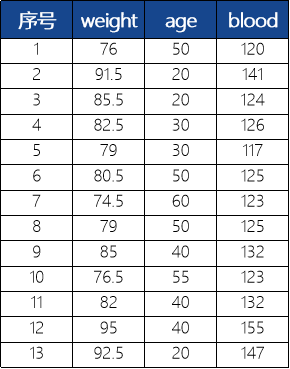

#### 4.2.1 多元回归模型

设因变量 $y$ 与自变量 $x_1, x_2, \ldots, x_p$ 的线性回归模型：

$$
y = β_0 + β_1 x_1 + β_2 x_2 + \ldots + β_p x_p + ε

$$
- $β_0$：回归常数
- $β_1, β_2, \ldots, β_p$：回归系数
- $ε$：随机误差（$ε \sim N(0, δ^2)$）

对于一个实际问题，如果有 $n$ 组观测数据 $(x_{i1}, x_{i2}, \ldots, x_{ip}; y_i) (i=1, 2, \ldots, n)$，则线性回归模型可表示为下式：

$$
\begin{cases}
y_1 = β_0 + β_1 x_{11} + β_2 x_{12} + \ldots + β_p x_{1p} + ε_1 \\
y_2 = β_0 + β_1 x_{21} + β_2 x_{22} + \ldots + β_p x_{2p} + ε_2 \\\vdots \\
y_n = β_0 + β_1 x_{n1} + β_2 x_{n2} + \ldots + β_p x_{np} + ε_n \\
\end{cases}

$$

上式写成矩阵形式为 $Y = Xβ + ε$，其中：

$$
Y =\begin{bmatrix}y_1 \\y_2 \\\vdots \\y_n
\end{bmatrix}, \quad

X =\begin{bmatrix}1 & x_{11} & x_{12} & \ldots & x_{1p} \\
1 & x_{21} & x_{22} & \ldots & x_{2p}  \\
\vdots & \vdots & \vdots &  & \vdots  \\
1 & x_{n1} & x_{n2} & \ldots & x_{np}\end{bmatrix}, \quad

β =\begin{bmatrix}β_0 \\β_1 \\\vdots \\β_p\end{bmatrix}, \quad

ε =\begin{bmatrix}ε_1 \\ε_2 \\\vdots \\ε_n\end{bmatrix}

$$

In [11]:
df = pd.read_csv('../data/pressure.csv') 
df

,weight,age,blood
0,76.0,50,120
1,91.5,20,141
2,85.5,20,124
3,82.5,30,126
4,79.0,30,117
5,80.5,50,125
6,74.5,60,123
7,79.0,50,125
8,85.0,40,132
9,76.5,55,123


#### 4.2.2 参数估计及显著性检验

当矩阵$X$列满秩时，$X^TX$为可逆方阵，所以参数方程的解为：

$$\hat{β} = {(X^TX)^{-1}X^TY}

$$

In [12]:
# 方法一：使用OLS() 基于数组求解
# 提取自变量与因变量
x = df.loc[:,df.columns != 'blood']
y = df['blood']

# 加入常量变量
X = sm.add_constant(x)
# 构建、拟合模型
model = sm.OLS(y, X)
result1 = model.fit()
print('回归参数的估计值为：\n',result1.params)

# 方法二：使用formula.ols() 基于公式求解
x1 = df['weight']
x2 = df['age']
y = df['blood']
# 构建、拟合模型
result2=sm.formula.ols('y~x1+x2',df).fit()
print('回归参数的估计值为：\n',list(result2.params))


# 方法三：使用LinearRegression()
md=LinearRegression().fit(x,y)
# 求预测值
y_fit=md.predict(x)       
# 输出回归系数
b0=md.intercept_; b12=md.coef_  
# 计算拟合优度R^2
R2=md.score(x,y)      
print("回归参数的估计值为：\n",[b0,b12[0],b12[1]])
print("拟合优度R^2=%.4f"%R2)

print('检验的结果为：\n',result1.summary())# 这里也可以用result2.summary()

回归参数的估计值为：
 const    -62.963359
weight     2.136558
age        0.400216
dtype: float64
回归参数的估计值为：
 [-62.96335911247593, 2.1365581383641477, 0.4002161546496845]
回归参数的估计值为：
 [-62.963359112475956, 2.136558138364147, 0.4002161546496851]
拟合优度R^2=0.9461
检验的结果为：
                             OLS Regression Results                            
Dep. Variable:                  blood   R-squared:                       0.946
Model:                            OLS   Adj. R-squared:                  0.935
Method:                 Least Squares   F-statistic:                     87.84
Date:                Fri, 07 Aug 2026   Prob (F-statistic):           4.53e-07
Time:                        01:57:46   Log-Likelihood:                -30.372
No. Observations:                  13   AIC:                             66.74
Df Residuals:                      10   BIC:                             68.44
Df Model:                           2                                         
Covariance Type:            nonr

d:\CodingRation\10-Python数学建模\Python_mathematical_modeling\.venv\lib\site-packages\scipy\stats\_stats_py.py:1736: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=13
  warnings.warn("kurtosistest only valid for n>=20 ... continuing "


#### 4.2.3 画线性回归图像

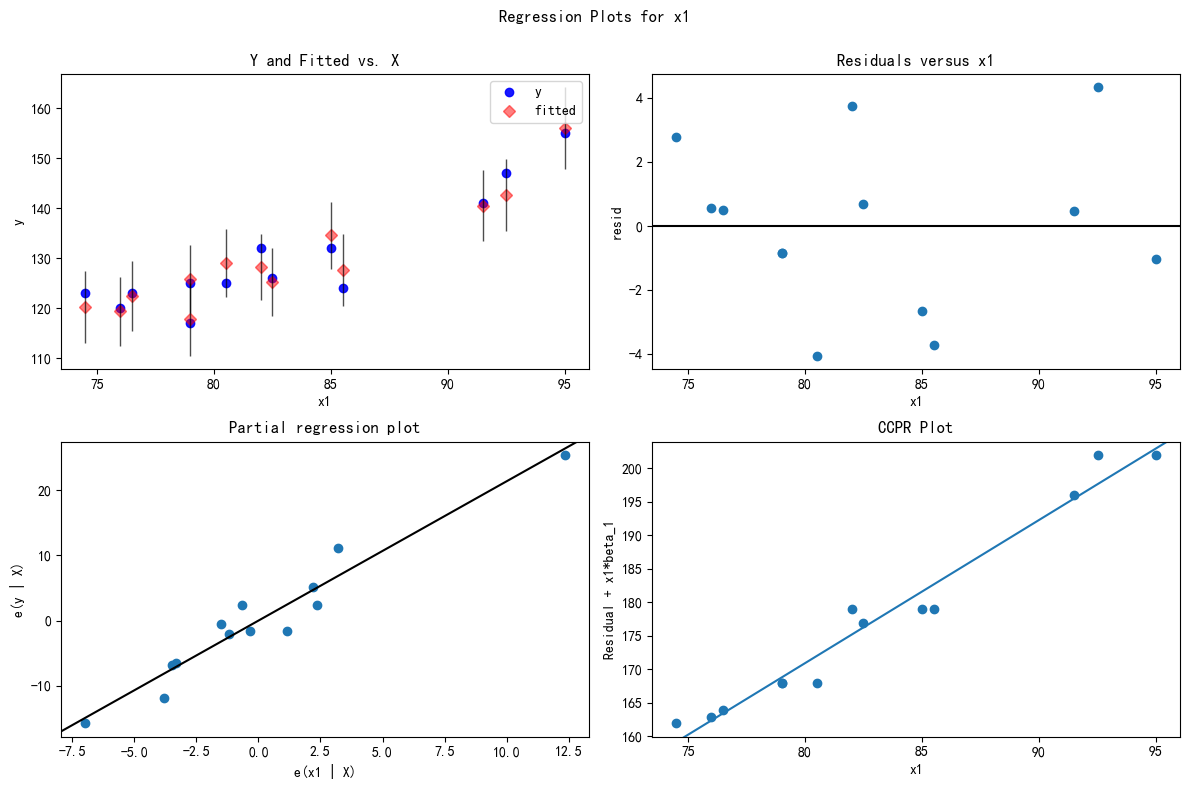

In [13]:
import matplotlib.pyplot as plt
# 画自变量x1的线性回归图像
fig = plt.figure(figsize=(12,8))
# plot_regress_exog(results, exog_idx, fig=None)
# exog_idx：模型中的自变量。
fig = sm.graphics.plot_regress_exog(result2, "x1", fig=fig)

- （1）左上一图 “Y and Fitted vs. X”，表示 y 观测值与线性回归模型拟合的估计值之间的差距。同时，可以发现二者是正相关的。
- （2）左下一图 “Partial regression plot” 表示偏回归图像，显示考虑新增其他自变量时，$x_1$ 与 $y$ 之间的关系。
- （3）右上一图 “Residuals versus $x_1$” 为关于自变量 $x_1$ 的残差图。横坐标为自变量 $x_1$ 的值，纵轴表示自变量 $x_1$ 对应的残差值，也就是左上一图中蓝圆点与橘色菱形间的距离差。
- （4）右下二图 “CCPR Plot” 图像是偏回归图像的拓展，反映了考虑新增其他自变量后两者的关系。

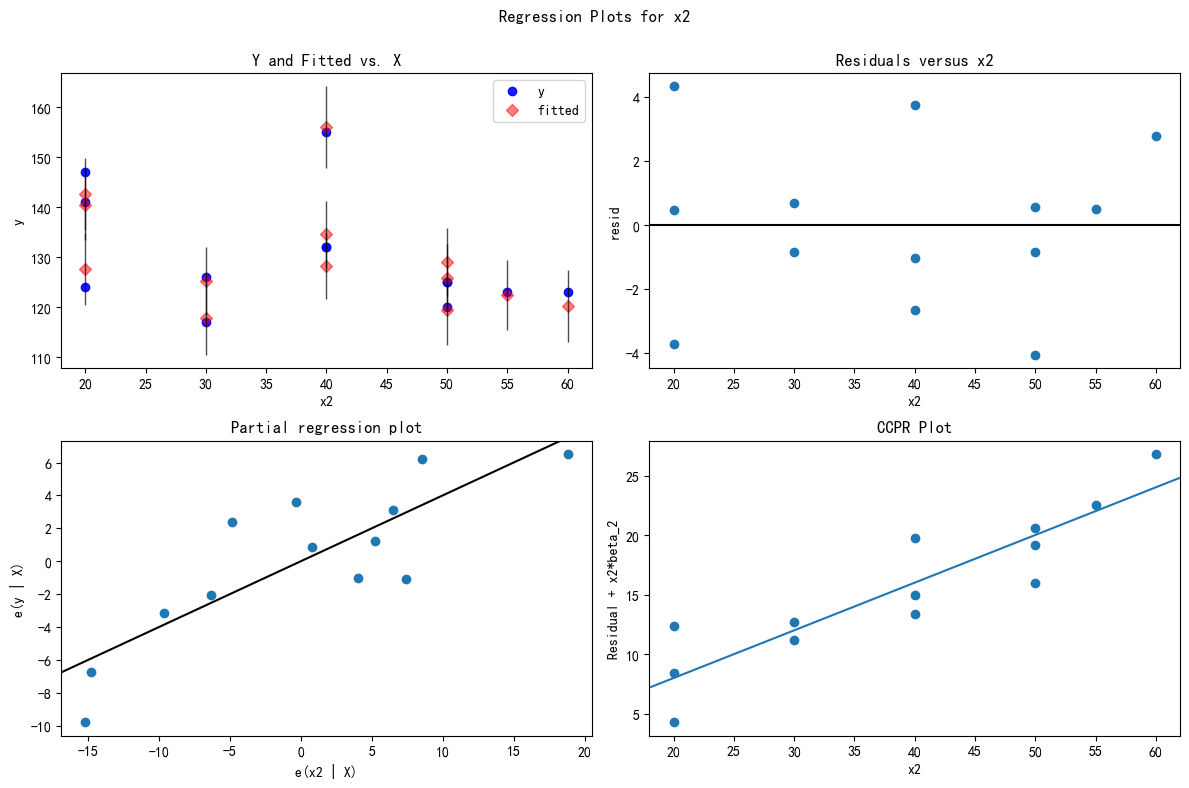

In [14]:
# 画自变量x2的线性回归图像
fig = plt.figure(figsize=(12,8))
fig = sm.graphics.plot_regress_exog(result2, "x2", fig=fig)

#### 4.2.4 参数区间估计

In [15]:
# 设置显著性水平为0.05
alpha = 0.05
n = len(x)
sem = t.isf(alpha/2,n-2-1)
# 设置参数值和标准误差 results.params获取参数值
a0 = result2.params[0];a0_std = 17.000
a1 = result2.params[1];a1_std = 0.175
a2 = result2.params[2];a2_std = 0.083
print('参数a0的区间估计为:',[a0-a0_std*sem,a0+a0_std*sem])
print('参数a1的区间估计为:',[a1-a1_std*sem,a1+a1_std*sem])
print('参数a2的区间估计为:',[a2-a2_std*sem,a2+a2_std*sem])

参数a0的区间估计为: [-100.84171959587988, -25.084998629071976]
参数a1的区间估计为: [1.7466338392702834, 2.5264824374580117]
参数a2的区间估计为: [0.2152806299365946, 0.5851516793627745]


C:\Users\yohoten\AppData\Local\Temp\ipykernel_37164\3700054821.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  a0 = result2.params[0];a0_std = 17.000
C:\Users\yohoten\AppData\Local\Temp\ipykernel_37164\3700054821.py:7: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  a1 = result2.params[1];a1_std = 0.175
C:\Users\yohoten\AppData\Local\Temp\ipykernel_37164\3700054821.py:8: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  a2 = result2.p

#### 4.2.5 预测

In [16]:
x2 = pd.DataFrame({'weight':[81],'age':[40]})
print('预计收缩压为:{}'.format(md.predict(x2)[0]))

预计收缩压为:126.10649628100737


## 5. 小结

本次实验介绍了一元线性回归和多元线性回归的思路以及一般步骤，实现了基于Python的线性回归模型的参数估计、模型显著性检验、参数区间估计和模型预测。

通过本次实验需要掌握以下内容：

- 掌握一元线性回归的思路和基本方法
- 掌握多元线性回归的思路和基本方法